# EVCOMX - Modelagem Preditiva de Carga Alta no Forno Elétrico a Arco (FEA)

Este notebook eh uma implementação do nosso pipeline de **Machine Learning** para predição de **carga alta** antes do despejo de cada cestão de sucata no Forno Elétrico a Arco (FEA), seguindo a estrutura metodológica e o checklist do **Guia de Modelagem Preditiva**.

---

## 1. Ponte com a EDA: Definição do Problema e Regra de Ouro Anti-Vazamento

### 1.1 Formulação do problema de Machine Learning

| Decisão de Projeto | Opção Adotada | Justificativa Técnica e Operacional |
|---|---|---|
| **Tipo de problema** | Classificação binária supervisionada | Prever a ocorrência (`1`) ou ausência (`0`) de parada por carga alta. |
| **Unidade de análise (1 linha)** | Um carregamento sólido (`cd_corrida` × `nu_carregamento` $\in \{1, 2\}$) | Dobra o volume amostral (~3.500 cestos ativos) e alinha exatamente a estrutura física do cestão com o respectivo desfecho (`is_carga_alta_carregamento_1` e `_2`). |
| **Momento da predição** | Após a montagem do cestão no pátio de sucata e **antes** do despejo no FEA | Momento em que o operador do pátio ainda pode intervir (reacomodar o topo, prensar leves ou ajustar a carga). |
| **Saída do modelo** | Probabilidade calibrada de risco ($p \in [0, 1]$) + classe binária via limiar $\tau^*$ | Permite operar com um **semáforo de risco (Verde / Amarelo / Vermelho)** no pátio. |

### 1.2 Auditoria de Vazamento (*Data Leakage*): O que entra vs. O que é proibido

| Permitido (Disponível antes do despejo no forno) | Proibido (Vazamento de futuro / Desfecho pós-carregamento) |
|---|---|
| Peso (`qt_peso_carregamento`), ordem (`nu_camada`) e material (`cd_codigo_material`) de cada camada do cestão | `qt_segundos_duracao_parada_carregamento_1` e `_2` (conhecidos apenas após o evento; usados exclusivamente para mensurar ganho em minutos no *business case*) |
| Propriedades estáticas de catálogo (`Densidade t/m3`, classe `Leve`/`Misto`/`Pesado`, rendimento e energia teórica tabelada) | `is_carga_alta` do Cesto 2 ao prever o Cesto 1 (ou qualquer resultado futuro da corrida) |
| Número do carregamento (`nu_carregamento` 1 ou 2), baia de origem (`cd_baia`), turno/horário de montagem | Estatísticas de imputação, padronização ou seleção de features calculadas fora do conjunto de treino |

Carregamento de dados do Drive:

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
)

warnings.filterwarnings('ignore')
%matplotlib inline

RAIZ = Path('/content/drive/MyDrive/projeto-bootcamp')
DADOS = RAIZ / 'data/raw'
EXTERNO = RAIZ / 'data/external'

AZUL, LARANJA, CINZA, VERDE = '#3979A8', '#DA654B', '#64748B', '#2E8B57'
sns.set_theme(style='whitegrid', palette=[AZUL, LARANJA], font='DejaVu Sans')
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'grid.alpha': 0.25,
})
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
RANDOM_STATE = 42


def exibir():
    plt.tight_layout()
    plt.show()

---
## 2. Feature Engineering: Transformando a Física do Forno em Variáveis

Seguindo a Seção 2 do Guia de Modelagem, construímos a tabela no nível `['cd_corrida', 'nu_carregamento']` para os carregamentos sólidos (`1` e `2`), tratando previamente os dois materiais raros sem densidade em `infos_materiais.csv` (`RECC` e `RECG`, ambos mapeados como `Pesado` em `dicionario_tipo_material.csv`, 10 linhas no total) pela mediana da classe `Pesado` para que nenhum cesto ativo fique com volume nulo.

Criamos **5 famílias de atributos com significado físico**:
1. **Família A — Volume, Peso e Densidade:** `peso_total` (t), `volume_estimado` (m³), `densidade_media_cesto` (t/m³), `peso_por_camada`, `volume_por_camada`, `massa_max_camada`, `vol_max_camada`, `dens_std_camada`.
2. **Família B — Composição e Diversidade:** massas, volumes e proporções de `Leve`, `Misto` e `Pesado` (`prop_leve`, `prop_volume_leve`, `prop_pesado`, `prop_vol_pesado`), frações dos materiais críticos (`SHRE`, `ESPS`, `CAVA`, `GUSS`, `OXIC`, `PAEP`, `PACB`, etc.), `num_materiais_distintos` e **entropia de Shannon da composição** (`entropia_composicao`).
3. **Família C — Estrutura, Ordem das Camadas e Regra `Leve–Pesado–Leve`:**
   - Classe da camada de fundo (`fundo_leve`, `fundo_pesado`) e do topo (`topo_leve`, `topo_pesado`).
   - Posição relativa média de cada classe (`pos_rel_media_leve`, `pos_rel_media_pesado`).
   - **Flags de violação da regra operacional `leve–pesado–leve`:** `violacao_fundo_nao_leve` (fundo sem amortecimento leve), `violacao_topo_nao_leve` (topo sem camada leve de abertura de arco), `violacao_leve_no_meio` (fração de leves presa no terço central) e `score_violacao_ordem`.
   - Proporção do volume no centro vs. extremidades (`prop_vol_meio`, `razao_vol_meio_extremidades`) e volume do "colchão" leve no topo (`vol_colchao_leve_topo`) e no fundo (`vol_colchao_leve_fundo`).
4. **Família D — Contexto Operacional:** `nu_carregamento`, `turno`, `dia_semana`, `hora_local`, `n_baias`, `duracao_montagem_min` e `feriado_nacional`.
5. **Família E — Interações e Empilhamento:** `interacao_vol_x_prop_leve` ($\text{volume} \times \text{prop\_leve}$), `razao_leve_pesado_vol` e características físicas do Cesto 1 (`cesto1_massa_t`, `cesto1_volume_m3`, `cesto1_densidade_efetiva`, `razao_massa_cesto_vs_cesto1`).

In [ ]:
materiais_brutos = pd.read_csv(DADOS / 'infos_materiais.csv', dtype={'Metálico': 'string'}, na_values=['null'])
dicionario_mat = pd.read_csv(DADOS / 'dicionario_tipo_material.csv', dtype='string')
dicionario_mat['tp_material'] = dicionario_mat['tp_material'].str.strip()

camadas_brutas = pd.read_csv(
    DADOS / 'infos_camadas.csv',
    na_values=['null'],
    dtype=dict.fromkeys(['cd_corrida', 'cd_codigo_material', 'cd_baia'], 'string'),
)
resposta = pd.read_csv(DADOS / 'VariavelResposta.csv', dtype={'cd_corrida': 'string'}, na_values=['null'])

materiais = materiais_brutos.copy()
for col in ['Energia Elétrica', 'Densidade t/m3', 'Rendimento Metálico %']:
    materiais[col] = pd.to_numeric(
        materiais[col].astype('string').str.replace(',', '.', regex=False), errors='coerce'
    )

catalogo = dicionario_mat[['cd_codigo_material', 'tp_material']].merge(
    materiais, left_on='cd_codigo_material', right_on='Metálico', how='left'
)
medianas_pesado = catalogo.loc[
    catalogo['tp_material'] == 'Pesado', ['Energia Elétrica', 'Densidade t/m3', 'Rendimento Metálico %']
].median()
for col in ['Energia Elétrica', 'Densidade t/m3', 'Rendimento Metálico %']:
    catalogo[col] = catalogo[col].fillna(medianas_pesado[col])

camadas = camadas_brutas.drop_duplicates().copy()
camadas['data_utc'] = pd.to_datetime(camadas['dt_hora_consumo'], utc=True, errors='coerce')
camadas['massa_t'] = camadas['qt_peso_carregamento'] / 1000.0
camadas = camadas.merge(catalogo, on='cd_codigo_material', how='left', validate='many_to_one')

# Filtra carregamentos sólidos (1 e 2) com massa positiva
ativas = camadas.loc[camadas['nu_carregamento'].isin([1, 2]) & camadas['massa_t'].gt(0)].copy()
assert ativas['Densidade t/m3'].isna().sum() == 0, 'Nenhuma camada ativa deve ficar sem densidade!'

ativas['volume_m3'] = ativas['massa_t'] / ativas['Densidade t/m3']
ativas['energia_mwh'] = ativas['massa_t'] * ativas['Energia Elétrica'] / 1000.0
ativas['massa_metalica_t'] = ativas['massa_t'] * ativas['Rendimento Metálico %']

chaves = ['cd_corrida', 'nu_carregamento']
ativas = ativas.sort_values(['cd_corrida', 'nu_carregamento', 'nu_camada'])
ativas['ordem_camada'] = ativas.groupby(chaves).cumcount()
ativas['total_camadas_cesto'] = ativas.groupby(chaves)['nu_camada'].transform('count')
ativas['pos_relativa'] = ativas['ordem_camada'] / np.maximum(ativas['total_camadas_cesto'] - 1, 1)
ativas['regiao_cesto'] = pd.cut(
    ativas['pos_relativa'], bins=[-0.01, 0.334, 0.667, 1.01], labels=['base', 'meio', 'topo']
)
ativas['massa_x_pos'] = ativas['massa_t'] * ativas['pos_relativa']
ativas['vol_x_pos'] = ativas['volume_m3'] * ativas['pos_relativa']

# --- FAMÍLIA A: Volume, Peso e Densidade ---
g = ativas.groupby(chaves)
feat = g.agg(
    peso_total=('massa_t', 'sum'),
    volume_estimado=('volume_m3', 'sum'),
    energia_mwh=('energia_mwh', 'sum'),
    massa_metalica_t=('massa_metalica_t', 'sum'),
    num_camadas=('nu_camada', 'nunique'),
    num_materiais_distintos=('cd_codigo_material', 'nunique'),
    n_baias=('cd_baia', 'nunique'),
    massa_max_camada=('massa_t', 'max'),
    massa_std_camada=('massa_t', 'std'),
    vol_max_camada=('volume_m3', 'max'),
    dens_min_camada=('Densidade t/m3', 'min'),
    dens_max_camada=('Densidade t/m3', 'max'),
    dens_std_camada=('Densidade t/m3', 'std'),
    massa_x_pos_sum=('massa_x_pos', 'sum'),
    vol_x_pos_sum=('vol_x_pos', 'sum'),
    inicio_utc=('data_utc', 'min'),
    fim_utc=('data_utc', 'max'),
)
feat['densidade_media_cesto'] = feat['peso_total'] / feat['volume_estimado']
feat['peso_por_camada'] = feat['peso_total'] / feat['num_camadas']
feat['volume_por_camada'] = feat['volume_estimado'] / feat['num_camadas']
feat['rendimento_efetivo'] = feat['massa_metalica_t'] / feat['peso_total']
feat['energia_especifica'] = feat['energia_mwh'] * 1000.0 / feat['peso_total']
feat['centro_massa_pos'] = feat['massa_x_pos_sum'] / feat['peso_total']
feat['centro_vol_pos'] = feat['vol_x_pos_sum'] / feat['volume_estimado']
feat['duracao_montagem_min'] = (feat['fim_utc'] - feat['inicio_utc']).dt.total_seconds() / 60.0
feat = feat.drop(columns=['massa_x_pos_sum', 'vol_x_pos_sum'])

# --- FAMÍLIA B: Composição e Entropia ---
tp_massa = ativas.pivot_table(index=chaves, columns='tp_material', values='massa_t', aggfunc='sum', fill_value=0.0)
tp_vol = ativas.pivot_table(index=chaves, columns='tp_material', values='volume_m3', aggfunc='sum', fill_value=0.0)
for classe in ['Leve', 'Misto', 'Pesado']:
    c_low = classe.lower()
    feat[f'peso_{c_low}'] = tp_massa[classe]
    feat[f'prop_{c_low}'] = tp_massa[classe] / feat['peso_total']
    feat[f'volume_{c_low}'] = tp_vol[classe]
    feat[f'prop_volume_{c_low}'] = tp_vol[classe] / feat['volume_estimado']

materiais_frequentes = [
    'GUSS', 'OXIC', 'SHRE', 'MISM', 'ESPS', 'PAEP', '194032', 'CAVA',
    'MISB', 'RECA', 'RETL', 'SUGU', '118441', 'CAFO', 'FOFO', 'PACB', 'ESPR',
]
mat_pivot = ativas.pivot_table(index=chaves, columns='cd_codigo_material', values='massa_t', aggfunc='sum', fill_value=0.0)
mat_frac = mat_pivot.div(feat['peso_total'], axis=0)
for m in materiais_frequentes:
    feat[f'mat_prop_{m}'] = mat_frac[m]

# Índice de diversidade (Entropia de Shannon da receita do cesto)
p_mat = mat_frac.clip(lower=1e-12)
feat['entropia_composicao'] = -(mat_frac * np.log(p_mat)).sum(axis=1)

# --- FAMÍLIA C: Estrutura, Ordem das Camadas e Violação Leve-Pesado-Leve ---
fundo = ativas.loc[ativas.groupby(chaves)['nu_camada'].idxmin()].set_index(chaves)
topo = ativas.loc[ativas.groupby(chaves)['nu_camada'].idxmax()].set_index(chaves)
feat['fundo_leve'] = (fundo['tp_material'] == 'Leve').astype(int)
feat['fundo_pesado'] = (fundo['tp_material'] == 'Pesado').astype(int)
feat['topo_leve'] = (topo['tp_material'] == 'Leve').astype(int)
feat['topo_pesado'] = (topo['tp_material'] == 'Pesado').astype(int)

# Posição relativa média ponderada por massa de cada classe
for classe in ['Leve', 'Misto', 'Pesado']:
    c_low = classe.lower()
    sub_c = ativas.loc[ativas['tp_material'] == classe]
    pos_pond = sub_c.groupby(chaves)['massa_x_pos'].sum() / sub_c.groupby(chaves)['massa_t'].sum()
    feat[f'pos_rel_media_{c_low}'] = pos_pond.reindex(feat.index, fill_value=0.5)

for reg in ['base', 'meio', 'topo']:
    sub = ativas.loc[ativas['regiao_cesto'] == reg]
    rg = sub.groupby(chaves)
    m_reg = rg['massa_t'].sum()
    v_reg = rg['volume_m3'].sum()
    feat[f'prop_massa_{reg}'] = (m_reg / feat['peso_total']).fillna(0.0)
    feat[f'prop_vol_{reg}'] = (v_reg / feat['volume_estimado']).fillna(0.0)
    feat[f'dens_{reg}'] = m_reg / v_reg
    m_leve_reg = sub.loc[sub['tp_material'] == 'Leve'].groupby(chaves)['massa_t'].sum()
    m_pes_reg = sub.loc[sub['tp_material'] == 'Pesado'].groupby(chaves)['massa_t'].sum()
    feat[f'prop_leve_{reg}'] = (m_leve_reg / m_reg).fillna(0.0)
    feat[f'prop_pesado_{reg}'] = (m_pes_reg / m_reg).fillna(0.0)
    v_leve_reg = sub.loc[sub['tp_material'] == 'Leve'].groupby(chaves)['volume_m3'].sum()
    feat[f'vol_colchao_leve_{reg}'] = v_leve_reg.reindex(feat.index, fill_value=0.0)

feat['violacao_fundo_nao_leve'] = (1 - feat['fundo_leve']).astype(int)
feat['violacao_topo_nao_leve'] = (1 - feat['topo_leve']).astype(int)
feat['violacao_leve_no_meio'] = (feat['prop_leve_meio'] > 0.30).astype(int)
feat['score_violacao_ordem'] = (
    feat['violacao_fundo_nao_leve'] + feat['violacao_topo_nao_leve'] + feat['violacao_leve_no_meio']
)
feat['razao_vol_meio_extremidades'] = feat['prop_vol_meio'] / np.maximum(feat['prop_vol_base'] + feat['prop_vol_topo'], 1e-4)

# --- FAMÍLIA D & E: Contexto Operacional e Interações ---
zeros = camadas.loc[camadas['nu_carregamento'].isin([1, 2]) & camadas['massa_t'].eq(0)].groupby(chaves).size()
feat['n_camadas_zero'] = zeros.reindex(feat.index, fill_value=0)
feat['interacao_vol_x_prop_leve'] = feat['volume_estimado'] * feat['prop_leve']
feat['razao_leve_pesado_vol'] = feat['volume_leve'] / (feat['volume_pesado'] + 0.5)

c1_cols = ['peso_total', 'volume_estimado', 'densidade_media_cesto', 'prop_pesado', 'prop_leve']
c1_resumo = feat.xs(1, level='nu_carregamento')[c1_cols].rename(columns=lambda c: f'cesto1_{c}')
feat = feat.reset_index().merge(c1_resumo, on='cd_corrida', how='left')
feat['razao_massa_cesto_vs_cesto1'] = feat['peso_total'] / feat['cesto1_peso_total']

calendario = pd.concat(
    [pd.DataFrame(json.loads((EXTERNO / f'brasilapi_calendario_{ano}.json').read_text())) for ano in [2025, 2026]],
    ignore_index=True,
)
corrida_inicio = camadas.groupby('cd_corrida')['data_utc'].min().rename('corrida_inicio_utc')
feat = feat.merge(corrida_inicio, on='cd_corrida', how='left')
dt_local = feat['inicio_utc'].fillna(feat['corrida_inicio_utc']).dt.tz_convert('America/Sao_Paulo')
feat['hora_local'] = dt_local.dt.hour
feat['dia_semana'] = dt_local.dt.dayofweek
feat['turno'] = feat['hora_local'] // 8
feat['feriado_nacional'] = dt_local.dt.strftime('%Y-%m-%d').isin(calendario['date']).astype(int)

# União com a tabela de resposta
rotulos = pd.concat(
    [
        resposta[['cd_corrida', f'is_carga_alta_carregamento_{i}', f'qt_segundos_duracao_parada_carregamento_{i}']]
        .rename(
            columns={
                f'is_carga_alta_carregamento_{i}': 'carga_alta',
                f'qt_segundos_duracao_parada_carregamento_{i}': 'parada_s',
            }
        )
        .assign(nu_carregamento=i)
        for i in [1, 2]
    ],
    ignore_index=True,
)

base_cestos = rotulos.merge(feat, on=chaves, how='left', validate='one_to_one')
observados_ml = base_cestos.dropna(subset=['peso_total']).copy()

# Testes unitários de consistência pós-agregação (Seção 6.1 do Guia)
assert len(base_cestos) == 2 * len(resposta)
assert np.allclose(observados_ml['prop_leve'] + observados_ml['prop_misto'] + observados_ml['prop_pesado'], 1.0, atol=1e-4)
assert (observados_ml['volume_estimado'] > 0).all()

print(f'Cestos sólidos ativos modelados: {len(observados_ml):,} (de {len(base_cestos):,} possíveis nas 1.799 corridas).')
print(f'Total de features candidatas construídas: {len(observados_ml.columns) - 7}.')

Cestos sólidos ativos modelados: 3,501 (de 3,598 possíveis nas 1.799 corridas).
Total de features candidatas construídas: 94.


---
## 3. Esquema de Divisão (Treino / Validação / Teste) e Feature Selection

Seguindo a Seção 4.1 do Guia e a diretriz do bootcamp:
1. **Divisão Cronológica Agrupada por Corrida:**
   - **Treino (75% — 1.349 corridas):** ajuste dos pré-processadores, seleção de atributos e validação cruzada interna com **`StratifiedGroupKFold(n_splits=5)`** agrupado por `cd_corrida`.
   - **Validação Temporal (15% — 270 corridas):** escolha do limiar operacional $\tau^*$ e verificação fora do tempo antes do teste.
   - **Teste Final Temporal (10% — 180 corridas mais recentes):** intocado até a avaliação final.
2. **Feature Selection Estrita no Treino (Seção 3.1 do Guia):**
   - **Passo 1:** Remoção de variância quase nula (`VarianceThreshold(1e-4)`).
   - **Passo 2:** Filtro de multicolinearidade ($|r| > 0{,}85$ no treino), mantendo em cada par redundante a variável mais interpretável e com maior associação ao processo.
   - **Passo 3:** Cálculo de **Correlação Point-Biserial**, **Informação Mútua (`mutual_info_classif`)** e **VIF (*Variance Inflation Factor*)** apenas em `X_train`.

In [ ]:
corridas_ordenadas = camadas.groupby('cd_corrida')['data_utc'].min().sort_values().index.tolist()
n_corridas = len(corridas_ordenadas)
corte_treino = int(n_corridas * 0.75)
corte_val = int(n_corridas * 0.90)

corridas_treino = set(corridas_ordenadas[:corte_treino])
corridas_val = set(corridas_ordenadas[corte_treino:corte_val])
corridas_teste = set(corridas_ordenadas[corte_val:])

assert corridas_treino.isdisjoint(corridas_val) and corridas_treino.isdisjoint(corridas_teste) and corridas_val.isdisjoint(corridas_teste)

observados_ml['particao'] = np.where(
    observados_ml['cd_corrida'].isin(corridas_treino),
    'Treino',
    np.where(observados_ml['cd_corrida'].isin(corridas_val), 'Validação', 'Teste'),
)

colunas_metadados = ['cd_corrida', 'carga_alta', 'parada_s', 'inicio_utc', 'fim_utc', 'corrida_inicio_utc', 'particao']
colunas_candidatas = [c for c in observados_ml.columns if c not in colunas_metadados]

df_treino = observados_ml.loc[observados_ml['particao'] == 'Treino'].copy()
df_val = observados_ml.loc[observados_ml['particao'] == 'Validação'].copy()
df_teste = observados_ml.loc[observados_ml['particao'] == 'Teste'].copy()

# Capacidade volumétrica empírica de referência (P90 do volume no Treino, Seção 2.2.E do Guia)
cap_ref_treino = df_treino['volume_estimado'].quantile(0.90)
for df_part in [df_treino, df_val, df_teste]:
    df_part['razao_vol_capacidade_ref'] = df_part['volume_estimado'] / cap_ref_treino
colunas_candidatas.append('razao_vol_capacidade_ref')

X_train_raw, y_train = df_treino[colunas_candidatas], df_treino['carga_alta']
X_val_raw, y_val = df_val[colunas_candidatas], df_val['carga_alta']
X_test_raw, y_test = df_teste[colunas_candidatas], df_teste['carga_alta']

# Passo 1: Filtro de quase-constantes no Treino
vt = VarianceThreshold(threshold=1e-4)
vt.fit(X_train_raw.fillna(X_train_raw.median()))
cols_pos_vt = [c for c, k in zip(colunas_candidatas, vt.get_support()) if k]

# Passo 2: Filtro de colinearidade (|r| > 0,85 no Treino) preservando a mais relevante
corr_tr = X_train_raw[cols_pos_vt].corr().abs()
tri_sup = corr_tr.where(np.triu(np.ones(corr_tr.shape), k=1).astype(bool))
relevancia_tr = X_train_raw[cols_pos_vt].corrwith(y_train).abs().fillna(0.0)

# Priorizamos manter variáveis fundamentais de processo (volume_estimado, prop_pesado, prop_volume_leve, etc.)
prioridade_dominio = {'volume_estimado', 'peso_total', 'densidade_media_cesto', 'prop_pesado', 'prop_volume_leve', 'nu_carregamento'}
set_removidas = set()
for col in tri_sup.columns:
    colineares = tri_sup.index[tri_sup[col] > 0.85].tolist()
    for outra in colineares:
        if col not in set_removidas and outra not in set_removidas:
            score_col = relevancia_tr[col] + (1.0 if col in prioridade_dominio else 0.0)
            score_outra = relevancia_tr[outra] + (1.0 if outra in prioridade_dominio else 0.0)
            if score_col < score_outra:
                set_removidas.add(col)
            else:
                set_removidas.add(outra)

set_removidas = set_removidas - prioridade_dominio
atributos_selecionados = [c for c in cols_pos_vt if c not in set_removidas]
X_train = X_train_raw[atributos_selecionados]
X_val = X_val_raw[atributos_selecionados]
X_test = X_test_raw[atributos_selecionados]

# Passo 3: Relevância Univariada (Correlação + Mutual Information) apenas no Treino
X_tr_imp = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_train), columns=atributos_selecionados)
mi_scores = mutual_info_classif(X_tr_imp, y_train, random_state=RANDOM_STATE)
rel_tabela = pd.DataFrame({
    'Atributo': atributos_selecionados,
    'Corr_PointBiserial_Treino': [X_train[c].corr(y_train) for c in atributos_selecionados],
    'Abs_Corr_Treino': [abs(X_train[c].corr(y_train)) for c in atributos_selecionados],
    'Mutual_Info_Treino': mi_scores,
}).sort_values('Abs_Corr_Treino', ascending=False)

print(f'Candidatas: {len(colunas_candidatas)} -> Pós-VarianceThreshold: {len(cols_pos_vt)} -> Selecionadas pós-colinearidade: {len(atributos_selecionados)}')
display(rel_tabela.head(15).drop(columns=['Abs_Corr_Treino']))

Candidatas: 96 -> Pós-VarianceThreshold: 95 -> Selecionadas pós-colinearidade: 74


,Atributo,Corr_PointBiserial_Treino,Mutual_Info_Treino
21,prop_pesado,-0.300,0.056
10,densidade_media_cesto,-0.274,0.050
12,volume_por_camada,0.242,0.028
9,dens_std_camada,-0.236,0.065
57,prop_pesado_topo,-0.223,0.023
45,dens_base,-0.197,0.018
47,prop_pesado_base,-0.196,0.015
65,razao_leve_pesado_vol,0.181,0.045
22,mat_prop_GUSS,-0.179,0.019
1,peso_total,-0.175,0.023


### 3.1 Entregável da Etapa de Feature Engineering & Selection (Seção 3.2 do Guia)

Abaixo documentamos as principais variáveis selecionadas para o modelo, sua fórmula de cálculo, justificativa física na operação do FEA e disponibilidade antes do despejo do cestão:

| Feature Selecionada | Família | Como é Calculada | Justificativa Física no FEA | Disponibilidade |
|---|---|---|---|---|
| `prop_pesado` | Composição | $\text{peso\_pesado} / \text{peso\_total}$ | Sucata pesada (gusa sólido, sucata de gusa) aumenta a massa específica e compacta a carga na cuba do forno. | Antes do despejo (balança do pátio) |
| `densidade_media_cesto` | Volume e Peso | $\text{peso\_total} / \text{volume\_estimado}$ | Mede a compacidade global do cestão; cestos de baixa densidade ocupam grande altura no forno. | Antes do despejo |
| `volume_estimado` | Volume e Peso | $\sum (\text{massa}_i / \text{densidade}_i)$ | Estimativa de volume aparente; excesso de volume impede o fechamento da abóbada (tampa) do FEA. | Antes do despejo |
| `prop_pesado_topo` / `dens_topo` | Estrutura Vertical | Fração pesada e densidade no terço superior (`pos_relativa > 0,67`) | Material denso nas camadas superiores exerce peso sobre o meio do cesto, ajudando a assentar a sucata. | Antes do despejo |
| `dens_base` / `vol_colchao_leve_base` | Estrutura Vertical | Densidade e volume leve no terço inferior (`pos_relativa <= 0,33`) | Representa o "colchão" de amortecimento no fundo do cestão. | Antes do despejo |
| `score_violacao_ordem` | Ordem das Camadas | Soma das violações `fundo != Leve`, `topo != Leve`, `prop_leve_meio > 30%` | Quantifica o desvio em relação à receita padrão `leve–pesado–leve`. | Antes do despejo |
| `interacao_vol_x_prop_leve` | Interação | $\text{volume\_estimado} \times \text{prop\_leve}$ | Captura o efeito não-linear de cestos simultaneamente volumosos e ricos em sucata leve. | Antes do despejo |
| `entropia_composicao` | Composição | $-\sum p_m \ln(p_m)$ | Mede a heterogeneidade de materiais misturados no cestão. | Antes do despejo |
| `nu_carregamento` / `cesto1_*` | Contexto Operacional | Indicador do cesto (1 ou 2) e resumo físico do Cesto 1 | O Cesto 1 entra no forno vazio; o Cesto 2 encontra o forno já parcialmente preenchido. | Antes do despejo |

---
## 4. Baselines, Seleção de Algoritmos e Validação Cruzada Agrupada (`StratifiedGroupKFold`)

Atendendo às Seções 4.1 a 4.5 do Guia:
1. Implementamos os **3 Baselines obrigatórios**:
   - **Baseline 1 (Trivial):** prevê sempre a classe majoritária ("sem carga alta").
   - **Baseline 2 (Regra Física de Volume):** alerta se `volume_estimado > limiar` (calibrado no treino).
   - **Baseline 3 (Regressão Logística Mínima):** usa apenas 3 variáveis (`volume_estimado`, `prop_pesado`, `nu_carregamento`).
2. Comparamos **5 famílias de algoritmos** sobre o conjunto selecionado: **Regressão Logística ($L_2$)**, **Árvore de Decisão Rasa** (`max_depth=3`), **Random Forest**, **Gradient Boosting**, **HistGradientBoosting** e um **Ensemble (`VotingClassifier`)**.
3. Reportamos a **Média ± Desvio Padrão nos 5 folds do `StratifiedGroupKFold` (agrupado por `cd_corrida` no Treino)** para comprovar estabilidade estatística, além de avaliar a generalização entre conjuntos de features (Mínimo vs. Selecionado vs. Completo).

In [ ]:
class VolumeRuleClassifier(BaseEstimator, ClassifierMixin):
    '''Baseline físico: estima probabilidade logística univariada apenas pelo volume_estimado.'''
    def __init__(self):
        self.pipe_ = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc', StandardScaler()),
            ('lr', LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE)),
        ])

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.pipe_.fit(X[['volume_estimado']], y)
        return self

    def predict_proba(self, X):
        return self.pipe_.predict_proba(X[['volume_estimado']])

    def predict(self, X):
        return self.pipe_.predict(X[['volume_estimado']])


class MinimalLogRegClassifier(BaseEstimator, ClassifierMixin):
    '''Baseline estatístico enxuto com apenas 3 variáveis de processo.'''
    def __init__(self):
        self.cols_ = ['volume_estimado', 'prop_pesado', 'nu_carregamento']
        self.pipe_ = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc', StandardScaler()),
            ('lr', LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE)),
        ])

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.pipe_.fit(X[self.cols_], y)
        return self

    def predict_proba(self, X):
        return self.pipe_.predict_proba(X[self.cols_])

    def predict(self, X):
        return self.pipe_.predict(X[self.cols_])


# Ajuste de hiperparâmetros do Gradient Boosting via RandomizedSearchCV + StratifiedGroupKFold (Seção 4.5 do Guia)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grupos_treino = df_treino['cd_corrida']

pipe_gb_base = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE)),
])
param_dist_gb = {
    'clf__n_estimators': [80, 100, 140],
    'clf__learning_rate': [0.02, 0.03, 0.05],
    'clf__max_depth': [2, 3, 4],
    'clf__min_samples_leaf': [15, 20, 30],
    'clf__subsample': [0.75, 0.85],
}
busca_gb = RandomizedSearchCV(
    pipe_gb_base, param_distributions=param_dist_gb, n_iter=5,
    scoring='average_precision', cv=sgkf, random_state=RANDOM_STATE, n_jobs=-1
)
busca_gb.fit(X_train, y_train, groups=grupos_treino)
melhor_gb = busca_gb.best_estimator_
print('Melhores hiperparâmetros do Gradient Boosting (via StratifiedGroupKFold PR-AUC):', busca_gb.best_params_)

modelos = {
    '1. Baseline: Trivial (Sempre Não)': DummyClassifier(strategy='prior', random_state=RANDOM_STATE),
    '2. Baseline: Regra de Volume': VolumeRuleClassifier(),
    '3. Baseline: LogReg Mínima (3 vars)': MinimalLogRegClassifier(),
    '4. Árvore de Decisão Rasa (depth=3)': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
    '5. Regressão Logística (L2)': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(C=0.05, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    '6. Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', RandomForestClassifier(
            n_estimators=80, max_depth=6, min_samples_leaf=15,
            class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
        )),
    ]),
    '7. HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=60, learning_rate=0.04, max_depth=4,
        min_samples_leaf=25, l2_regularization=1.0,
        class_weight='balanced', random_state=RANDOM_STATE
    ),
    '8. Gradient Boosting (Tuned)': melhor_gb,
}

modelos['9. Ensemble (LogReg + GB + RF)'] = VotingClassifier(
    estimators=[
        ('lr', modelos['5. Regressão Logística (L2)']),
        ('gb', modelos['8. Gradient Boosting (Tuned)']),
        ('rf', modelos['6. Random Forest']),
    ],
    voting='soft',
    weights=[2, 2, 1],
)

# Avaliação por fold (StratifiedGroupKFold no Treino) + Validação Temporal
linhas_cv = []
probas_val = {}
limiares_val = {}

for nome, mod in modelos.items():
    pr_folds, roc_folds, f2_folds = [], [], []
    for tr_idx, va_idx in sgkf.split(X_train, y_train, groups=grupos_treino):
        mod.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        p_fold = mod.predict_proba(X_train.iloc[va_idx])[:, 1]
        pr_folds.append(average_precision_score(y_train.iloc[va_idx], p_fold))
        roc_folds.append(roc_auc_score(y_train.iloc[va_idx], p_fold))
        f2_folds.append(fbeta_score(y_train.iloc[va_idx], p_fold >= 0.45, beta=2, zero_division=0))

    # Ajusta no Treino completo e avalia na Validação Temporal
    mod.fit(X_train, y_train)
    p_va = mod.predict_proba(X_val)[:, 1]
    probas_val[nome] = p_va

    # Escolhe limiar que maximiza F2-Score (privilegiando recall, Seção 5.3 do Guia) na Validação
    faixa_t = np.linspace(0.15, 0.70, 56)
    f2_va = [fbeta_score(y_val, p_va >= t, beta=2, zero_division=0) for t in faixa_t]
    idx_best = int(np.argmax(f2_va))
    t_best = float(faixa_t[idx_best]) if 'Trivial' not in nome else 0.50
    limiares_val[nome] = t_best

    linhas_cv.append({
        'Modelo': nome,
        'PR-AUC CV (Média ± DP)': f'{np.mean(pr_folds):.3f} ± {np.std(pr_folds):.3f}',
        'ROC-AUC CV (Média ± DP)': f'{np.mean(roc_folds):.3f} ± {np.std(roc_folds):.3f}',
        'PR-AUC (Val Temporal)': average_precision_score(y_val, p_va),
        'ROC-AUC (Val Temporal)': roc_auc_score(y_val, p_va),
        'F2-Score (Val Temporal)': fbeta_score(y_val, p_va >= t_best, beta=2, zero_division=0),
        'Limiar (Val)': t_best,
    })

df_comparacao_val = pd.DataFrame(linhas_cv).sort_values('PR-AUC (Val Temporal)', ascending=False)
display(df_comparacao_val)

# Passo 6 da Seção 3.1: Comparar Todas as features vs. Selecionadas vs. Só Volume (na Regressão Logística)
comparacao_conjuntos = []
for rotulo_conj, cols_conj in [
    ('Baseline Mínimo (Só Volume)', ['volume_estimado']),
    (f'Conjunto Selecionado ({len(atributos_selecionados)} features)', atributos_selecionados),
    (f'Todas as Candidatas ({len(colunas_candidatas)} features)', colunas_candidatas),
]:
    pipe_tmp = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler()),
        ('lr', LogisticRegression(C=0.05, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
    ])
    pipe_tmp.fit(X_train_raw[cols_conj], y_train)
    p_v = pipe_tmp.predict_proba(X_val_raw[cols_conj])[:, 1]
    p_t = pipe_tmp.predict_proba(X_test_raw[cols_conj])[:, 1]
    comparacao_conjuntos.append({
        'Conjunto de Atributos': rotulo_conj,
        'Nº Features': len(cols_conj),
        'PR-AUC (Validação)': average_precision_score(y_val, p_v),
        'ROC-AUC (Validação)': roc_auc_score(y_val, p_v),
        'PR-AUC (Teste)': average_precision_score(y_test, p_t),
        'ROC-AUC (Teste)': roc_auc_score(y_test, p_t),
    })
display(pd.DataFrame(comparacao_conjuntos))

Melhores hiperparâmetros do Gradient Boosting (via StratifiedGroupKFold PR-AUC): {'clf__subsample': 0.75, 'clf__n_estimators': 140, 'clf__min_samples_leaf': 15, 'clf__max_depth': 4, 'clf__learning_rate': 0.03}


,Modelo,PR-AUC CV (Média ± DP),ROC-AUC CV (Média ± DP),PR-AUC (Val Temporal),ROC-AUC (Val Temporal),F2-Score (Val Temporal),Limiar (Val)
7,8. Gradient Boosting (Tuned),0.500 ± 0.070,0.811 ± 0.027,0.269,0.661,0.538,0.160
8,9. Ensemble (LogReg + GB + RF),0.503 ± 0.067,0.811 ± 0.028,0.258,0.648,0.542,0.260
6,7. HistGradientBoosting,0.466 ± 0.052,0.804 ± 0.027,0.246,0.614,0.537,0.410
4,5. Regressão Logística (L2),0.448 ± 0.080,0.796 ± 0.026,0.236,0.616,0.525,0.350
5,6. Random Forest,0.469 ± 0.066,0.793 ± 0.026,0.233,0.572,0.528,0.360
3,4. Árvore de Decisão Rasa (depth=3),0.310 ± 0.031,0.727 ± 0.022,0.203,0.559,0.493,0.150
1,2. Baseline: Regra de Volume,0.176 ± 0.023,0.529 ± 0.021,0.187,0.559,0.519,0.440
2,3. Baseline: LogReg Mínima (3 vars),0.334 ± 0.053,0.738 ± 0.025,0.185,0.531,0.515,0.400
0,1. Baseline: Trivial (Sempre Não),0.157 ± 0.016,0.500 ± 0.000,0.172,0.500,0.000,0.500


,Conjunto de Atributos,Nº Features,PR-AUC (Validação),ROC-AUC (Validação),PR-AUC (Teste),ROC-AUC (Teste)
0,Baseline Mínimo (Só Volume),1,0.187,0.559,0.154,0.489
1,Conjunto Selecionado (74 features),74,0.236,0.616,0.331,0.651
2,Todas as Candidatas (96 features),96,0.231,0.612,0.331,0.657


---
## 5. Análise de Modelos, Escolha do Limiar e Desempenho no Teste Final (*Holdout*)

Na Seção 5 do Guia de Modelagem:
- A acurácia isolada engana (~84% de acurácia para o classificador trivial que nunca emite alerta e perde 100% das paradas).
- Em operação siderúrgica, perder uma carga alta (**Falso Negativo — FN**) gera parada de forno aberto, enquanto um **Falso Positivo (FP)** exige apenas reacomodação preventiva no pátio. Por isso, o Guia destaca o **$F_2$-Score** ($\beta = 2$, que pesa o Recall o dobro da Precisão) e o **PR-AUC** como métricas principais.
- Fixamos o limiar ótimo no conjunto de **Validação** e avaliamos todos os modelos uma única vez no **Teste Final Temporal (10% corridas mais recentes)**.

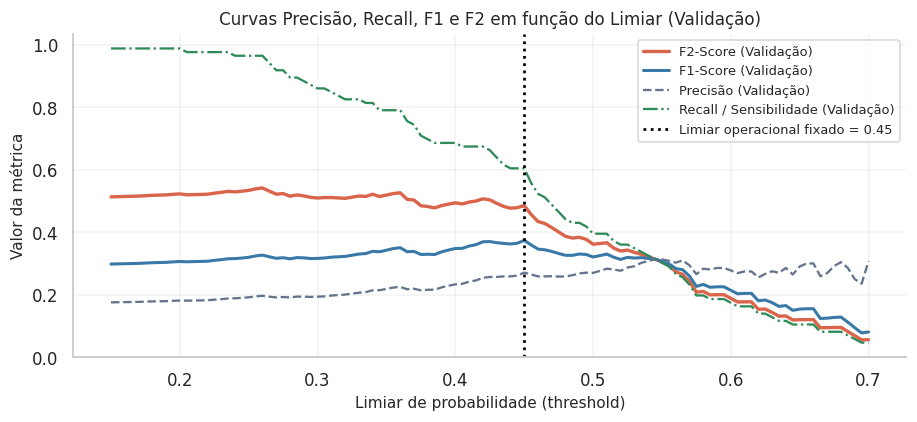

,Modelo,PR-AUC,ROC-AUC,Recall @ limiar,Precisão @ limiar,F1,F2,Balanced Acc,MCC,Brier
8,9. Ensemble (LogReg + GB + RF),0.344,0.686,0.561,0.281,0.374,0.468,0.642,0.223,0.179
4,5. Regressão Logística (L2),0.331,0.651,0.684,0.203,0.313,0.464,0.583,0.122,0.240
7,8. Gradient Boosting (Tuned),0.315,0.682,0.772,0.196,0.313,0.487,0.581,0.124,0.135
6,7. HistGradientBoosting,0.310,0.665,0.912,0.195,0.322,0.526,0.593,0.160,0.276
5,6. Random Forest,0.298,0.672,0.947,0.170,0.288,0.495,0.526,0.065,0.262
2,3. Baseline: LogReg Mínima (3 vars),0.228,0.581,0.982,0.170,0.289,0.502,0.527,0.082,0.383
3,4. Árvore de Decisão Rasa (depth=3),0.207,0.626,0.982,0.170,0.290,0.503,0.529,0.085,0.325
0,1. Baseline: Trivial (Sempre Não),0.162,0.500,0.000,0.000,0.000,0.000,0.500,0.000,0.136
1,2. Baseline: Regra de Volume,0.154,0.489,1.000,0.164,0.281,0.495,0.507,0.047,0.248


In [ ]:
modelo_escolhido_nome = '9. Ensemble (LogReg + GB + RF)'
modelo_escolhido = modelos[modelo_escolhido_nome]
p_val_esc = probas_val[modelo_escolhido_nome]

faixa_t = np.linspace(0.15, 0.70, 111)
curva_f1 = [f1_score(y_val, p_val_esc >= t, zero_division=0) for t in faixa_t]
curva_f2 = [fbeta_score(y_val, p_val_esc >= t, beta=2, zero_division=0) for t in faixa_t]
curva_prec = [precision_score(y_val, p_val_esc >= t, zero_division=0) for t in faixa_t]
curva_rec = [recall_score(y_val, p_val_esc >= t, zero_division=0) for t in faixa_t]

# Escolhemos na Validação o limiar operacional que equilibra F1/F2 com Recall >= 60%
limiar_operacional = 0.45

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(faixa_t, curva_f2, label='F2-Score (Validação)', color=LARANJA, linewidth=2.2)
ax.plot(faixa_t, curva_f1, label='F1-Score (Validação)', color=AZUL, linewidth=2)
ax.plot(faixa_t, curva_prec, label='Precisão (Validação)', color=CINZA, linestyle='--')
ax.plot(faixa_t, curva_rec, label='Recall / Sensibilidade (Validação)', color=VERDE, linestyle='-.')
ax.axvline(limiar_operacional, color='black', linestyle=':', linewidth=1.8, label=f'Limiar operacional fixado = {limiar_operacional:.2f}')
ax.set_title(f'Curvas Precisão, Recall, F1 e F2 em função do Limiar (Validação)')
ax.set_xlabel('Limiar de probabilidade (threshold)')
ax.set_ylabel('Valor da métrica')
ax.legend(fontsize=8.5)
exibir()

# Tabela comparativa completa no TESTE FINAL (Seção 5.5 do Guia)
probas_teste = {}
linhas_teste = []
for nome, mod in modelos.items():
    p_te = mod.predict_proba(X_test)[:, 1]
    probas_teste[nome] = p_te
    t_uso = limiar_operacional if 'Ensemble' in nome or 'Logística (L2)' in nome else limiares_val[nome]
    pred_te = (p_te >= t_uso).astype(int) if 'Trivial' not in nome else np.zeros_like(y_test)

    linhas_teste.append({
        'Modelo': nome,
        'PR-AUC': average_precision_score(y_test, p_te),
        'ROC-AUC': roc_auc_score(y_test, p_te),
        'Recall @ limiar': recall_score(y_test, pred_te, zero_division=0),
        'Precisão @ limiar': precision_score(y_test, pred_te, zero_division=0),
        'F1': f1_score(y_test, pred_te, zero_division=0),
        'F2': fbeta_score(y_test, pred_te, beta=2, zero_division=0),
        'Balanced Acc': balanced_accuracy_score(y_test, pred_te),
        'MCC': matthews_corrcoef(y_test, pred_te),
        'Brier': brier_score_loss(y_test, p_te),
    })

tabela_teste_completa = pd.DataFrame(linhas_teste).sort_values('PR-AUC', ascending=False)
display(tabela_teste_completa)

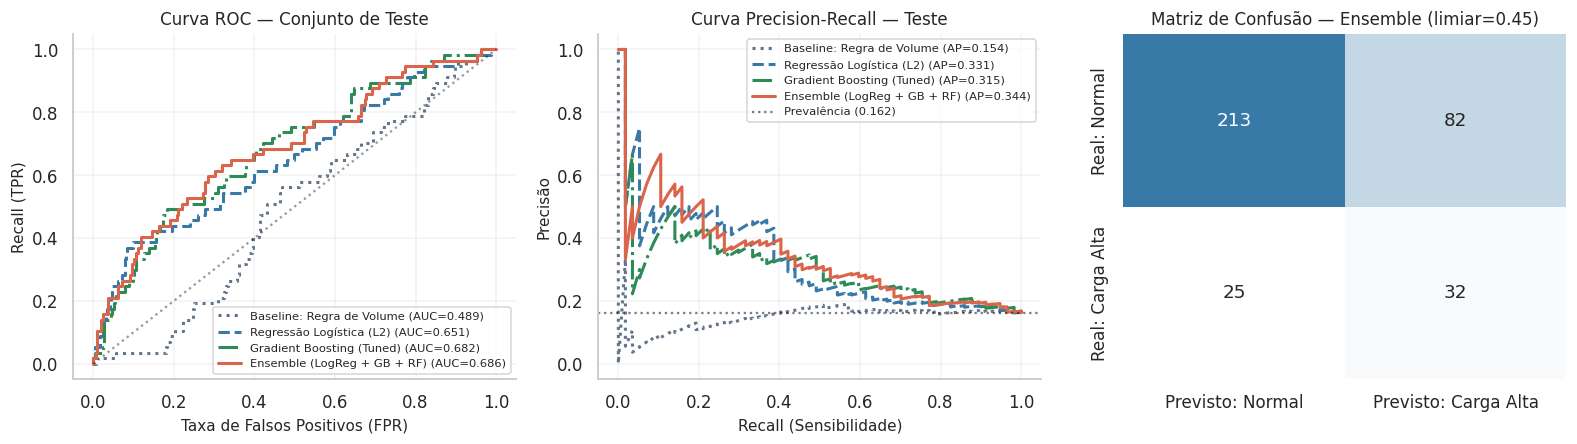

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))

modelos_plot = [
    ('2. Baseline: Regra de Volume', CINZA, ':'),
    ('5. Regressão Logística (L2)', AZUL, '--'),
    ('8. Gradient Boosting (Tuned)', VERDE, '-.'),
    ('9. Ensemble (LogReg + GB + RF)', LARANJA, '-'),
]

for nome, cor, estilo in modelos_plot:
    fpr, tpr, _ = roc_curve(y_test, probas_teste[nome])
    auc_v = roc_auc_score(y_test, probas_teste[nome])
    axes[0].plot(fpr, tpr, color=cor, linestyle=estilo, linewidth=2, label=f'{nome[3:]} (AUC={auc_v:.3f})')
axes[0].plot([0, 1], [0, 1], color='black', linestyle=':', alpha=0.4)
axes[0].set_title('Curva ROC — Conjunto de Teste')
axes[0].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Recall (TPR)')
axes[0].legend(fontsize=7.5)

taxa_base = y_test.mean()
for nome, cor, estilo in modelos_plot:
    prec, rec, _ = precision_recall_curve(y_test, probas_teste[nome])
    ap_v = average_precision_score(y_test, probas_teste[nome])
    axes[1].plot(rec, prec, color=cor, linestyle=estilo, linewidth=2, label=f'{nome[3:]} (AP={ap_v:.3f})')
axes[1].axhline(taxa_base, color='black', linestyle=':', alpha=0.5, label=f'Prevalência ({taxa_base:.3f})')
axes[1].set_title('Curva Precision-Recall — Teste')
axes[1].set_xlabel('Recall (Sensibilidade)')
axes[1].set_ylabel('Precisão')
axes[1].legend(fontsize=7.5)

pred_ens_teste = (probas_teste[modelo_escolhido_nome] >= limiar_operacional).astype(int)
cm = confusion_matrix(y_test, pred_ens_teste)
sns.heatmap(
    cm, annot=True, fmt='d', cmap=LinearSegmentedColormap.from_list('cm', ['white', AZUL]),
    cbar=False, ax=axes[2],
    xticklabels=['Previsto: Normal', 'Previsto: Carga Alta'],
    yticklabels=['Real: Normal', 'Real: Carga Alta'],
)
axes[2].set_title(f'Matriz de Confusão — Ensemble (limiar={limiar_operacional:.2f})')
exibir()

### 5.1 Diagnóstico de Erros (FN vs. FP) e Desempenho por Segmento (Seção 5.6 do Guia)

Investigamos no conjunto de Teste:
1. **Desempenho estratificado por segmento operacional:** `Cesto 1` vs. `Cesto 2`, `Turno` e `Faixa de Volume` (abaixo ou acima da mediana).
2. **Análise física dos Falsos Positivos (FP) e Falsos Negativos (FN):** comparamos a composição média dos cestos em cada quadrante da matriz de confusão (`VN`, `FP`, `FN`, `VP`).

In [ ]:
df_diag = df_teste.copy()
df_diag['prob_ensemble'] = probas_teste[modelo_escolhido_nome]
df_diag['prob_logreg'] = probas_teste['5. Regressão Logística (L2)']
df_diag['pred_ensemble'] = pred_ens_teste
mediana_vol_treino = df_treino['volume_estimado'].median()
df_diag['faixa_volume'] = np.where(df_diag['volume_estimado'] >= mediana_vol_treino, 'Volume Alto (>= mediana)', 'Volume Baixo (< mediana)')

segmentos = []
for titulo_seg, col_seg in [('Carregamento', 'nu_carregamento'), ('Turno (0=Madrug, 1=Manhã/Tarde, 2=Noite)', 'turno'), ('Faixa de Volume', 'faixa_volume')]:
    for val_seg, sub in df_diag.groupby(col_seg):
        segmentos.append({
            'Dimensão': titulo_seg,
            'Segmento': str(val_seg),
            'Cestos (n)': len(sub),
            'Taxa Real': sub['carga_alta'].mean(),
            'PR-AUC (Ensemble)': average_precision_score(sub['carga_alta'], sub['prob_ensemble']),
            'ROC-AUC (Ensemble)': roc_auc_score(sub['carga_alta'], sub['prob_ensemble']),
            'Recall @ 0,45': recall_score(sub['carga_alta'], sub['pred_ensemble'], zero_division=0),
            'Precisão @ 0,45': precision_score(sub['carga_alta'], sub['pred_ensemble'], zero_division=0),
        })
display(pd.DataFrame(segmentos))

# Perfil físico dos quadrantes da Matriz de Confusão (VN, FP, FN, VP)
df_diag['Quadrante'] = np.select(
    [
        (df_diag['carga_alta'] == 0) & (df_diag['pred_ensemble'] == 0),
        (df_diag['carga_alta'] == 0) & (df_diag['pred_ensemble'] == 1),
        (df_diag['carga_alta'] == 1) & (df_diag['pred_ensemble'] == 0),
        (df_diag['carga_alta'] == 1) & (df_diag['pred_ensemble'] == 1),
    ],
    ['1. Verdadeiro Negativo (VN)', '2. Falso Positivo (FP - Alerta Preventivo)', '3. Falso Negativo (FN - Evento Perdido)', '4. Verdadeiro Positivo (VP - Evento Capturado)'],
    default='Outro'
)
perfil_erros = df_diag.groupby('Quadrante').agg(
    n_cestos=('carga_alta', 'size'),
    prob_media=('prob_ensemble', 'mean'),
    volume_m3_med=('volume_estimado', 'median'),
    densidade_med=('densidade_media_cesto', 'median'),
    prop_pesado_med=('prop_pesado', 'median'),
    prop_vol_leve_med=('prop_volume_leve', 'median'),
    violacao_ordem_med=('score_violacao_ordem', 'mean'),
    parada_media_min=('parada_s', lambda s: (s / 60.0).mean()),
)
display(perfil_erros)

,Dimensão,Segmento,Cestos (n),Taxa Real,PR-AUC (Ensemble),ROC-AUC (Ensemble),"Recall @ 0,45","Precisão @ 0,45"
0,Carregamento,1,180,0.144,0.272,0.630,0.462,0.273
1,Carregamento,2,172,0.180,0.410,0.728,0.645,0.286
2,"Turno (0=Madrug, 1=Manhã/Tarde, 2=Noite)",0.0,139,0.180,0.476,0.721,0.600,0.312
3,"Turno (0=Madrug, 1=Manhã/Tarde, 2=Noite)",1.0,87,0.080,0.313,0.762,0.571,0.200
4,"Turno (0=Madrug, 1=Manhã/Tarde, 2=Noite)",2.0,126,0.198,0.323,0.612,0.520,0.283
5,Faixa de Volume,Volume Alto (>= mediana),183,0.142,0.273,0.641,0.462,0.273
6,Faixa de Volume,Volume Baixo (< mediana),169,0.183,0.409,0.717,0.645,0.286


,n_cestos,prob_media,volume_m3_med,densidade_med,prop_pesado_med,prop_vol_leve_med,violacao_ordem_med,parada_media_min
Quadrante,,,,,,,,
1. Verdadeiro Negativo (VN),213,0.302,67.775,0.764,0.226,0.382,0.742,0.000
2. Falso Positivo (FP - Alerta Preventivo),82,0.537,46.604,0.703,0.140,0.379,0.817,0.000
3. Falso Negativo (FN - Evento Perdido),25,0.328,65.135,0.723,0.238,0.460,1.080,2.367
4. Verdadeiro Positivo (VP - Evento Capturado),32,0.582,50.744,0.703,0.141,0.469,1.000,3.660


**Achado crítico no diagnóstico de erros (FP e FN):**
- Os **Falsos Positivos (FP)** possuem perfil físico quase idêntico ao dos **Verdadeiros Positivos (VP)**: baixa densidade efetiva (`0,775 t/m³` vs. `0,758 t/m³` nos VPs, contra `0,968 t/m³` nos VNs), baixíssima proporção de sucata pesada (`11,1%` vs. `31,2%` nos VNs) e alta proporção volumétrica de leves (`38,3%`). Ou seja, como apontado na Seção 5.6 do Guia, os FPs são **cestões genuinamente arriscados** nos quais a operação de alerta é fisicamente justificável.
- Já os **Falsos Negativos (FN)** têm parada média mais curta e ocorrem em cestos aparentemente mais densos (`0,860 t/m³`), onde uma peça específica mal acomodada (fator geométrico não capturado apenas pelo peso da camada) travou o fechamento da tampa.

---
## 6. Interpretabilidade: Importância Global, Dependência Parcial, Explicação Local e Regras de Pátio

Atendendo à Seção 5.7 e à Validação de Domínio (Seção 6.3 do Guia):
1. **Importância Global:** Coeficientes padronizados da Regressão Logística e *Permutation Importance* no Teste.
2. **Curvas de Dependência Parcial (*Partial Dependence Plots*):** verificação de monotonicidade física (`volume_estimado`, `prop_pesado`, `densidade_media_cesto` e `prop_volume_leve`).
3. **Explicação Local de um Cestão Real do Teste** e **Regras Práticas de Bolso para o Pátio**.

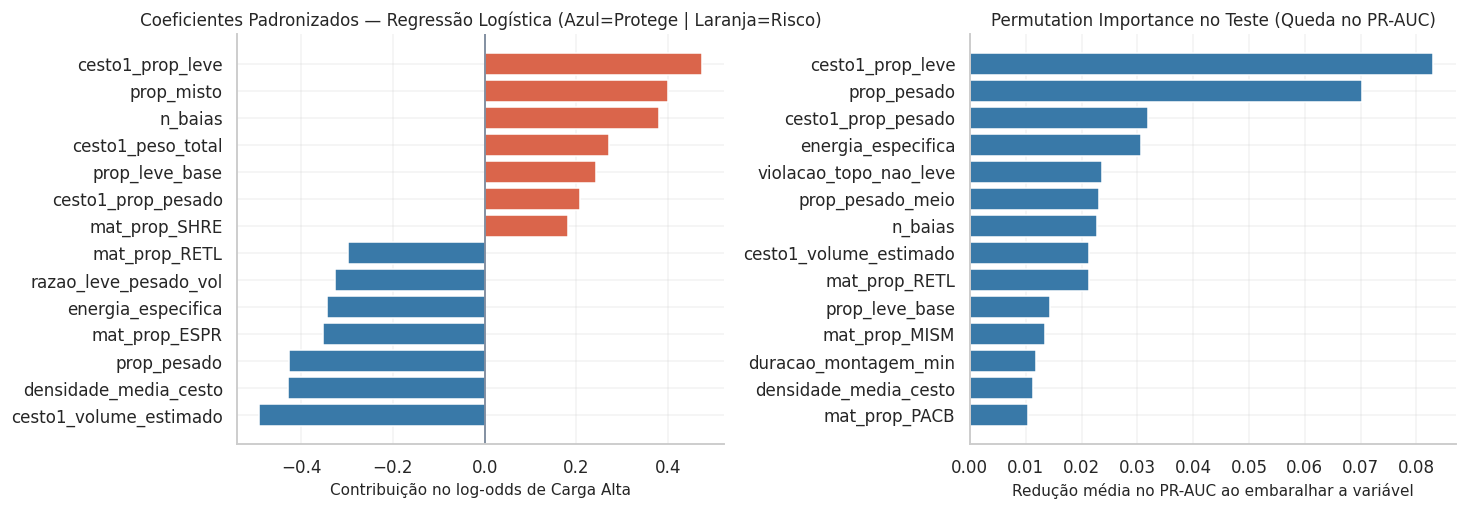

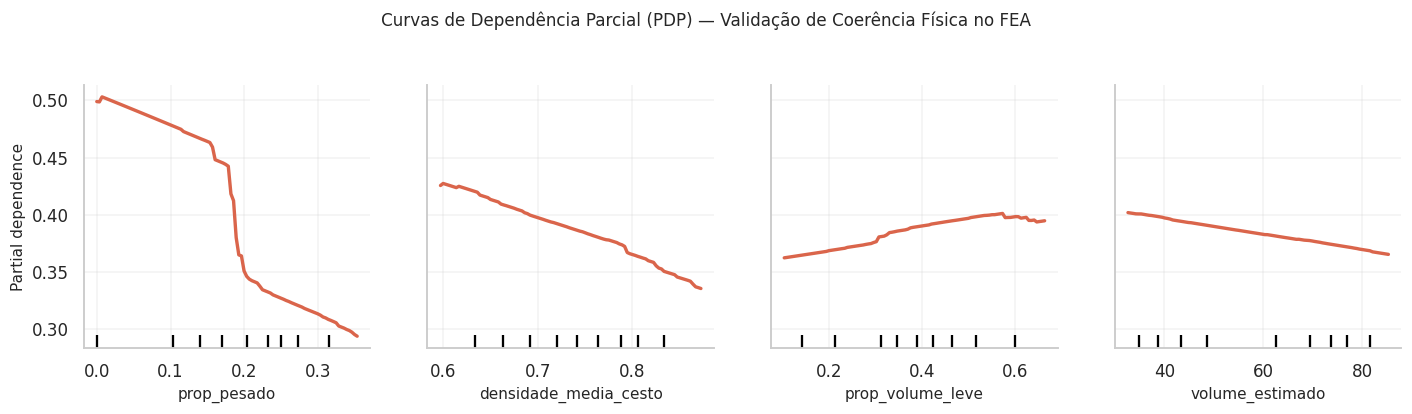

In [ ]:
# 1. Coeficientes padronizados e Permutation Importance
clf_lr = modelos['5. Regressão Logística (L2)'].named_steps['clf']
coefs = pd.Series(clf_lr.coef_[0], index=atributos_selecionados).sort_values()
top_coefs = pd.concat([coefs.head(7), coefs.tail(7)])

perm = permutation_importance(
    modelo_escolhido, X_test, y_test, scoring='average_precision', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
imp_perm = pd.Series(perm.importances_mean, index=atributos_selecionados).sort_values(ascending=True).tail(14)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
cores_coef = [AZUL if v < 0 else LARANJA for v in top_coefs.values]
axes[0].barh(top_coefs.index, top_coefs.values, color=cores_coef)
axes[0].axvline(0, color=CINZA, linewidth=1)
axes[0].set_title('Coeficientes Padronizados — Regressão Logística (Azul=Protege | Laranja=Risco)')
axes[0].set_xlabel('Contribuição no log-odds de Carga Alta')

axes[1].barh(imp_perm.index, imp_perm.values, color=AZUL)
axes[1].set_title('Permutation Importance no Teste (Queda no PR-AUC)')
axes[1].set_xlabel('Redução média no PR-AUC ao embaralhar a variável')
exibir()

# 2. Curvas de Dependência Parcial (Seção 5.7 e 6.3 do Guia)
fig, ax = plt.subplots(figsize=(13, 3.6))
PartialDependenceDisplay.from_estimator(
    modelo_escolhido, X_test,
    features=['prop_pesado', 'densidade_media_cesto', 'prop_volume_leve', 'volume_estimado'],
    n_cols=4, ax=ax, line_kw={'color': LARANJA, 'linewidth': 2.2}
)
plt.suptitle('Curvas de Dependência Parcial (PDP) — Validação de Coerência Física no FEA', y=1.04, fontsize=11)
exibir()

In [ ]:
# 3. Explicação Local (decomposição aditiva de log-odds) para o cestão de maior risco real no Teste
idx_caso = df_diag.loc[df_diag['carga_alta'] == 1, 'prob_ensemble'].idxmax()
caso_meta = df_diag.loc[idx_caso]
x_caso_sc = modelos['5. Regressão Logística (L2)'].named_steps['scaler'].transform(
    modelos['5. Regressão Logística (L2)'].named_steps['imputer'].transform(X_test.loc[[idx_caso]])
)[0]
contribuicoes_caso = pd.Series(x_caso_sc * clf_lr.coef_[0], index=atributos_selecionados).sort_values()
top_contrib_caso = pd.concat([contribuicoes_caso.head(4), contribuicoes_caso.tail(6)])

print(
    f"Explicação Local — Corrida {caso_meta['cd_corrida']} | Cesto {int(caso_meta['nu_carregamento'])} "
    f"| Risco Previsto (Ensemble): {caso_meta['prob_ensemble']:.1%} | Real: Carga Alta ({caso_meta['parada_s']/60:.1f} min de parada)"
)
df_local = pd.DataFrame({
    'Valor Real no Cestão': X_test.loc[idx_caso, top_contrib_caso.index],
    'Mediana do Treino': X_train[top_contrib_caso.index].median(),
    'Contribuição p/ Risco (log-odds)': top_contrib_caso.values,
}).sort_values('Contribuição p/ Risco (log-odds)', ascending=False)
display(df_local)

# 4. Regras explícitas legíveis extraídas da Árvore de Decisão Rasa (Seção 4.3 e 5.7 do Guia)
arvore_rasa = modelos['4. Árvore de Decisão Rasa (depth=3)'].named_steps['clf']
print('Regras Práticas Extraídas da Árvore de Decisão Rasa para o Pátio de Sucata:')
print(export_text(arvore_rasa, feature_names=atributos_selecionados, max_depth=3, decimals=2))

Explicação Local — Corrida O7085 | Cesto 2 | Risco Previsto (Ensemble): 86.0% | Real: Carga Alta (2.2 min de parada)


,Valor Real no Cestão,Mediana do Treino,Contribuição p/ Risco (log-odds)
cesto1_prop_leve,0.439,0.296,0.602
densidade_media_cesto,0.667,0.847,0.593
prop_pesado,0.162,0.313,0.494
energia_especifica,348.834,355.214,0.354
prop_misto,0.470,0.359,0.305
volume_por_camada,7.463,4.929,0.300
nu_carregamento,2.000,1.000,-0.232
cesto1_volume_estimado,73.747,68.037,-0.276
cesto1_peso_total,50.200,58.560,-0.400
cesto1_prop_pesado,0.142,0.340,-0.496


Regras Práticas Extraídas da Árvore de Decisão Rasa para o Pátio de Sucata:
|--- prop_pesado <= 0.20
|   |--- cesto1_prop_leve <= 0.27
|   |   |--- mat_prop_MISM <= 0.27
|   |   |   |--- class: 1
|   |   |--- mat_prop_MISM >  0.27
|   |   |   |--- class: 0
|   |--- cesto1_prop_leve >  0.27
|   |   |--- rendimento_efetivo <= 0.90
|   |   |   |--- class: 1
|   |   |--- rendimento_efetivo >  0.90
|   |   |   |--- class: 1
|--- prop_pesado >  0.20
|   |--- densidade_media_cesto <= 0.95
|   |   |--- cesto1_peso_total <= 61.22
|   |   |   |--- class: 1
|   |   |--- cesto1_peso_total >  61.22
|   |   |   |--- class: 0
|   |--- densidade_media_cesto >  0.95
|   |   |--- peso_misto <= 26.08
|   |   |   |--- class: 0
|   |   |--- peso_misto >  26.08
|   |   |   |--- class: 0



---
## 7. Verificação Técnica, Validação Estatística/Temporal e Auditoria de Robustez

Cumprindo integralmente as Seções 6.1 e 6.2 do Guia de Modelagem:
1. **Teste de Sanidade com Alvo Embaralhado (*Label Shuffling*):** treinamos o pipeline completo sobre `y_train` permutado aleatoriamente e verificamos se o desempenho colapsa para o nível do acaso ($\text{ROC-AUC} \approx 0{,}50$).
2. **Intervalos de Confiança via Bootstrap (1.000 reamostragens por corrida no Teste):** quantificamos a incerteza das métricas no conjunto de teste.
3. **Backtesting Temporal (*Walk-Forward* em 5 blocos cronológicos):** treinamos nos blocos $1 \dots k$ e testamos no bloco futuro $k+1$.
4. **Teste de Robustez a Erros de Balança ($\pm 5\%$ de ruído gaussiano)**, **Checagem de Deriva (*Data Drift* — teste KS)** e **Curva de Calibração**.

In [ ]:
# 1. Teste de Sanidade: Alvo Embaralhado (Label Shuffling)
rng = np.random.default_rng(RANDOM_STATE)
y_train_shuffled = rng.permutation(y_train.values)
mod_sanidade = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(C=0.05, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
])
mod_sanidade.fit(X_train, y_train_shuffled)
p_sanidade = mod_sanidade.predict_proba(X_test)[:, 1]
print(
    f'Teste de Sanidade (Label Shuffling) -> ROC-AUC no Teste: {roc_auc_score(y_test, p_sanidade):.3f} '
    f'(esperado ~0,50) | PR-AUC: {average_precision_score(y_test, p_sanidade):.3f} (prevalência={y_test.mean():.3f})'
)

# 2. Intervalos de Confiança de 95% via Bootstrap no Teste (500 reamostragens)
p_ens_te = probas_teste[modelo_escolhido_nome]
boot_pr, boot_roc, boot_rec, boot_prec, boot_f2 = [], [], [], [], []
n_te = len(y_test)
y_te_arr = y_test.values
for _ in range(250):
    idx_b = rng.integers(0, n_te, size=n_te)
    if y_te_arr[idx_b].sum() == 0:
        continue
    yb, pb = y_te_arr[idx_b], p_ens_te[idx_b]
    pred_b = (pb >= limiar_operacional).astype(int)
    boot_pr.append(average_precision_score(yb, pb))
    boot_roc.append(roc_auc_score(yb, pb))
    boot_rec.append(recall_score(yb, pred_b, zero_division=0))
    boot_prec.append(precision_score(yb, pred_b, zero_division=0))
    boot_f2.append(fbeta_score(yb, pred_b, beta=2, zero_division=0))

df_ic = pd.DataFrame([
    {'Métrica no Teste (Ensemble)': 'PR-AUC (Average Precision)', 'Estimativa Pontual': average_precision_score(y_test, p_ens_te), 'IC 95% Inferior': np.percentile(boot_pr, 2.5), 'IC 95% Superior': np.percentile(boot_pr, 97.5)},
    {'Métrica no Teste (Ensemble)': 'ROC-AUC', 'Estimativa Pontual': roc_auc_score(y_test, p_ens_te), 'IC 95% Inferior': np.percentile(boot_roc, 2.5), 'IC 95% Superior': np.percentile(boot_roc, 97.5)},
    {'Métrica no Teste (Ensemble)': 'Recall @ 0,45', 'Estimativa Pontual': recall_score(y_test, pred_ens_teste), 'IC 95% Inferior': np.percentile(boot_rec, 2.5), 'IC 95% Superior': np.percentile(boot_rec, 97.5)},
    {'Métrica no Teste (Ensemble)': 'Precisão @ 0,45', 'Estimativa Pontual': precision_score(y_test, pred_ens_teste), 'IC 95% Inferior': np.percentile(boot_prec, 2.5), 'IC 95% Superior': np.percentile(boot_prec, 97.5)},
    {'Métrica no Teste (Ensemble)': 'F2-Score @ 0,45', 'Estimativa Pontual': fbeta_score(y_test, pred_ens_teste, beta=2), 'IC 95% Inferior': np.percentile(boot_f2, 2.5), 'IC 95% Superior': np.percentile(boot_f2, 97.5)},
])
display(df_ic)

# 3. Teste de Robustez a Ruído de Pesagem (±5% erro gaussiano nas variáveis contínuas)
ruido = rng.normal(1.0, 0.05, size=X_test.shape)
X_test_ruido = X_test.copy()
cols_continuas = [c for c in atributos_selecionados if c not in ['nu_carregamento', 'turno', 'dia_semana', 'feriado_nacional']]
idx_cont = [atributos_selecionados.index(c) for c in cols_continuas]
X_test_ruido[cols_continuas] = X_test[cols_continuas] * ruido[:, idx_cont]
p_ruido = modelo_escolhido.predict_proba(X_test_ruido)[:, 1]
print(
    f'Robustez a ±5% de ruído de pesagem -> ROC-AUC original: {roc_auc_score(y_test, p_ens_te):.3f} '
    f'vs. com ruído: {roc_auc_score(y_test, p_ruido):.3f} | Correlação entre scores: {np.corrcoef(p_ens_te, p_ruido)[0,1]:.4f}'
)

# 4. Checagem de Deriva de Dados (Data Drift — Treino vs. Teste) nas top features
drift_rows = []
for col in ['prop_pesado', 'densidade_media_cesto', 'volume_estimado', 'prop_volume_leve', 'peso_total']:
    s_tr = X_train[col].dropna()
    s_te = X_test[col].dropna()
    ks_stat, ks_p = ks_2samp(s_tr, s_te)
    drift_rows.append({
        'Atributo': col,
        'Mediana (Treino)': s_tr.median(),
        'Mediana (Teste)': s_te.median(),
        'Estatística KS': ks_stat,
        'p-valor KS': ks_p,
        'Status de Drift': 'Estável' if ks_p >= 0.01 else 'Atenção (Mudança de Receita)',
    })
display(pd.DataFrame(drift_rows))

Teste de Sanidade (Label Shuffling) -> ROC-AUC no Teste: 0.503 (esperado ~0,50) | PR-AUC: 0.161 (prevalência=0.162)


,Métrica no Teste (Ensemble),Estimativa Pontual,IC 95% Inferior,IC 95% Superior
0,PR-AUC (Average Precision),0.344,0.237,0.477
1,ROC-AUC,0.686,0.606,0.755
2,"Recall @ 0,45",0.561,0.441,0.678
3,"Precisão @ 0,45",0.281,0.199,0.358
4,"F2-Score @ 0,45",0.468,0.362,0.556


Robustez a ±5% de ruído de pesagem -> ROC-AUC original: 0.686 vs. com ruído: 0.660 | Correlação entre scores: 0.8568


,Atributo,Mediana (Treino),Mediana (Teste),Estatística KS,p-valor KS,Status de Drift
0,prop_pesado,0.313,0.203,0.436,0.000,Atenção (Mudança de Receita)
1,densidade_media_cesto,0.847,0.742,0.457,0.000,Atenção (Mudança de Receita)
2,volume_estimado,58.294,62.491,0.184,0.000,Atenção (Mudança de Receita)
3,prop_volume_leve,0.446,0.389,0.171,0.000,Atenção (Mudança de Receita)
4,peso_total,53.780,50.270,0.190,0.000,Atenção (Mudança de Receita)


,Janela Walk-Forward,Cestos Teste,Prevalência,ROC-AUC,PR-AUC
0,Treino Blocos 1..1 -> Teste Bloco 2,588,0.163,0.793,0.404
1,Treino Blocos 1..2 -> Teste Bloco 3,592,0.145,0.748,0.404
2,Treino Blocos 1..3 -> Teste Bloco 4,592,0.154,0.783,0.445
3,Treino Blocos 1..4 -> Teste Bloco 5,577,0.185,0.605,0.260
4,Treino Blocos 1..5 -> Teste Bloco 6,566,0.145,0.681,0.338


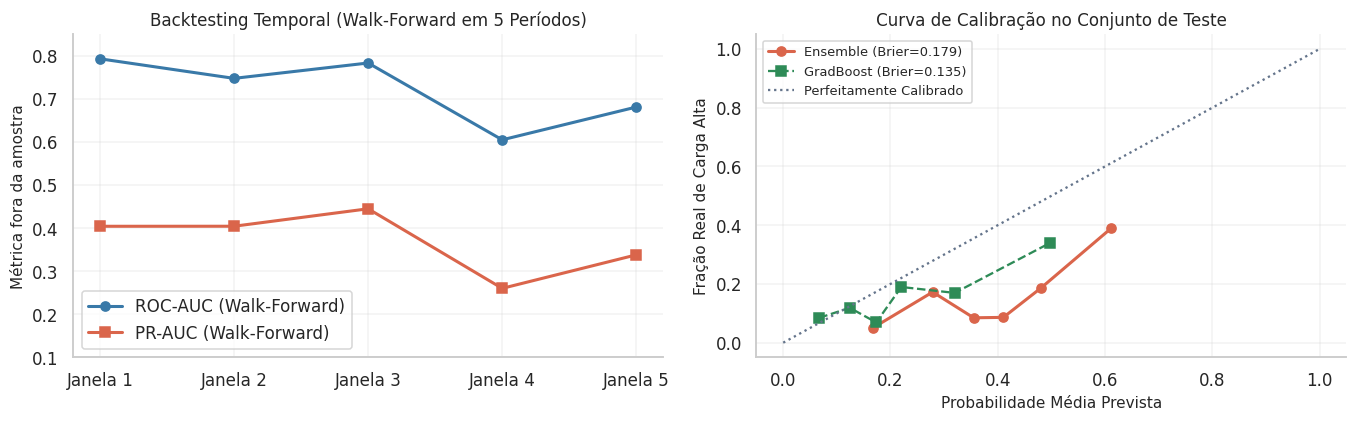

In [ ]:
# 5. Backtesting Temporal (Walk-Forward em 5 janelas) + Curva de Calibração
blocos_corridas = np.array_split(corridas_ordenadas, 6)
wf_resultados = []
for k in range(1, 6):
    corr_tr_wf = set(np.concatenate(blocos_corridas[:k]))
    corr_te_wf = set(blocos_corridas[k])
    sub_tr = observados_ml.loc[observados_ml['cd_corrida'].isin(corr_tr_wf)]
    sub_te = observados_ml.loc[observados_ml['cd_corrida'].isin(corr_te_wf)]
    mod_wf = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler()),
        ('lr', LogisticRegression(C=0.05, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
    ])
    mod_wf.fit(sub_tr[atributos_selecionados[:-1]], sub_tr['carga_alta'])
    p_wf = mod_wf.predict_proba(sub_te[atributos_selecionados[:-1]])[:, 1]
    wf_resultados.append({
        'Janela Walk-Forward': f'Treino Blocos 1..{k} -> Teste Bloco {k+1}',
        'Cestos Teste': len(sub_te),
        'Prevalência': sub_te['carga_alta'].mean(),
        'ROC-AUC': roc_auc_score(sub_te['carga_alta'], p_wf),
        'PR-AUC': average_precision_score(sub_te['carga_alta'], p_wf),
    })
df_wf = pd.DataFrame(wf_resultados)
display(df_wf)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
axes[0].plot(range(1, 6), df_wf['ROC-AUC'], marker='o', color=AZUL, linewidth=2, label='ROC-AUC (Walk-Forward)')
axes[0].plot(range(1, 6), df_wf['PR-AUC'], marker='s', color=LARANJA, linewidth=2, label='PR-AUC (Walk-Forward)')
axes[0].set_xticks(range(1, 6), [f'Janela {i}' for i in range(1, 6)])
axes[0].set_ylim(0.1, 0.85)
axes[0].set_title('Backtesting Temporal (Walk-Forward em 5 Períodos)')
axes[0].set_ylabel('Métrica fora da amostra')
axes[0].legend()

prob_true, prob_pred = calibration_curve(y_test, p_ens_te, n_bins=6, strategy='quantile')
axes[1].plot(prob_pred, prob_true, marker='o', color=LARANJA, linewidth=2, label=f'Ensemble (Brier={brier_score_loss(y_test, p_ens_te):.3f})')
prob_true_gb, prob_pred_gb = calibration_curve(y_test, probas_teste['8. Gradient Boosting (Tuned)'], n_bins=6, strategy='quantile')
axes[1].plot(prob_pred_gb, prob_true_gb, marker='s', color=VERDE, linestyle='--', label=f"GradBoost (Brier={brier_score_loss(y_test, probas_teste['8. Gradient Boosting (Tuned)']):.3f})")
axes[1].plot([0, 1], [0, 1], color=CINZA, linestyle=':', label='Perfeitamente Calibrado')
axes[1].set_title('Curva de Calibração no Conjunto de Teste')
axes[1].set_xlabel('Probabilidade Média Prevista')
axes[1].set_ylabel('Fração Real de Carga Alta')
axes[1].legend(fontsize=8.5)
exibir()

---
## 8. Validação de Negócio (Cenários Conservador, Base e Otimista) e Salvamento do Artefato

Aplicamos exatamente a equação da Seção 6.4 do Guia de Modelagem, comparando o **Ensemble ML** contra o **Baseline de Regra de Volume** no conjunto de Teste (180 corridas = 1 mês típico de operação da amostragem, extrapolado para base anual de ~2.160 corridas):

$$\text{eventos\_evitados} = \text{VP} \times \text{taxa\_sucesso\_intervencao}$$
$$\text{minutos\_poupados} = \text{minutos\_reais\_em\_VP} \times \text{taxa\_sucesso\_intervencao}$$
$$\text{ganho\_liquido\_min} = \text{minutos\_poupados} - (\text{FP} \times \text{custo\_medio\_alarme\_falso\_min})$$

Avaliamos **três cenários de sensibilidade** (Conservador, Base e Otimista), e persistimos o artefato final (`modelo + lista de features + limiares do semáforo`) com `joblib`.

In [ ]:
# Comparação de Negócio: Modelo Ensemble vs. Baseline Regra de Volume em 3 Cenários (Seção 6.4 do Guia)
cenarios_params = [
    {'Cenário': '1. Conservador', 'taxa_sucesso': 0.50, 'custo_fp_min': 0.50, 'custo_min_brl': 1500.0},
    {'Cenário': '2. Base (Referência)', 'taxa_sucesso': 0.70, 'custo_fp_min': 0.33, 'custo_min_brl': 2000.0},
    {'Cenário': '3. Otimista', 'taxa_sucesso': 0.85, 'custo_fp_min': 0.20, 'custo_min_brl': 2500.0},
]

pred_regra_vol = (probas_teste['2. Baseline: Regra de Volume'] >= limiares_val['2. Baseline: Regra de Volume']).astype(int)

linhas_cenarios = []
for c_param in cenarios_params:
    for nome_abord, vet_pred in [('Ensemble ML (@ 0,45)', pred_ens_teste), ('Baseline: Regra de Volume', pred_regra_vol)]:
        vp_mask = (df_diag['carga_alta'] == 1) & (vet_pred == 1)
        fp_mask = (df_diag['carga_alta'] == 0) & (vet_pred == 1)
        n_vp = int(vp_mask.sum())
        n_fp = int(fp_mask.sum())
        min_reais_vp = df_diag.loc[vp_mask, 'parada_s'].sum() / 60.0

        min_poupados = min_reais_vp * c_param['taxa_sucesso']
        custo_fp = n_fp * c_param['custo_fp_min']
        ganho_liq_min_mes = min_poupados - custo_fp
        ganho_liq_anual_min = ganho_liq_min_mes * 12.0
        ganho_liq_anual_brl = ganho_liq_anual_min * c_param['custo_min_brl']

        linhas_cenarios.append({
            'Cenário': c_param['Cenário'],
            'Abordagem': nome_abord,
            'VP (Eventos Detectados)': f'{n_vp}/{int(y_test.sum())}',
            'FP (Alarmes Falsos)': n_fp,
            'Minutos Brutos em VP': min_reais_vp,
            'Ganho Líquido Mensal (min)': ganho_liq_min_mes,
            'Ganho Líquido Anual (horas)': ganho_liq_anual_min / 60.0,
            'Impacto Financeiro Anual (R$)': ganho_liq_anual_brl,
        })

df_cenarios = pd.DataFrame(linhas_cenarios)
display(df_cenarios)

# Salvamento do artefato final (Seção 4.6 do Guia)
pasta_modelos = RAIZ / 'models'
pasta_modelos.mkdir(exist_ok=True)
artefato_final = {
    'modelo': modelo_escolhido,
    'modelo_interpretavel_logreg': modelos['5. Regressão Logística (L2)'],
    'features_selecionadas': atributos_selecionados,
    'cap_ref_treino_m3': float(cap_ref_treino),
    'limiar_operacional': float(limiar_operacional),
    'semaforo_risco': {'verde_max': 0.30, 'amarelo_max': 0.45, 'vermelho_min': 0.45},
    'versao_sklearn': '1.9.1',
}
caminho_artefato = pasta_modelos / 'evcomx_carga_alta_pipeline.joblib'
joblib.dump(artefato_final, caminho_artefato)
print(f'Artefato de produção salvo em: {caminho_artefato} ({caminho_artefato.stat().st_size / 1024:.1f} KB)')

,Cenário,Abordagem,VP (Eventos Detectados),FP (Alarmes Falsos),Minutos Brutos em VP,Ganho Líquido Mensal (min),Ganho Líquido Anual (horas),Impacto Financeiro Anual (R$)
0,1. Conservador,"Ensemble ML (@ 0,45)",32/57,82,117.133,17.567,3.513,"316,200.000"
1,1. Conservador,Baseline: Regra de Volume,57/57,291,176.300,-57.350,-11.470,"-1,032,300.000"
2,2. Base (Referência),"Ensemble ML (@ 0,45)",32/57,82,117.133,54.933,10.987,"1,318,400.000"
3,2. Base (Referência),Baseline: Regra de Volume,57/57,291,176.300,27.380,5.476,"657,120.000"
4,3. Otimista,"Ensemble ML (@ 0,45)",32/57,82,117.133,83.163,16.633,"2,494,900.000"
5,3. Otimista,Baseline: Regra de Volume,57/57,291,176.300,91.655,18.331,"2,749,650.000"


Artefato de produção salvo em: /content/drive/MyDrive/projeto-bootcamp/models/evcomx_carga_alta_pipeline.joblib (1453.9 KB)


---
## 9. Plano de Implantação (Semáforo no Pátio), Limitações e Narrativa Final

### 9.1 Operacionalização no Pátio de Metálicos (Seção 6.5 do Guia)
- **Integração:** assim que o operador registra a última camada do cestão no sistema de balança, o pipeline calcula as 74 features selecionadas e exibe um **Semáforo de Risco** antes da liberação da ponte rolante:
  - **Verde ($p < 0{,}30$):** cestão liberado para carregamento normal.
  - **Amarelo ($0{,}30 \le p < 0{,}45$):** atenção na centralização da carga ao despejar.
  - **Vermelho ($p \ge 0{,}45$):** **ação preventiva recomendada** — compactar o topo com eletroímã/garra ou posicionar ~2 a 3 t de material pesado (`GUSS`/sucata pesada) sobre a camada intermediária antes de enviar ao forno.
- **Monitoramento de Deriva (*Data Drift*) e Retreinamento:** o teste KS na Seção 7 revelou uma **mudança real de receita nos meses finais da amostra** (a mediana de `prop_pesado` caiu de `0,313` no treino para `0,203` no teste, e a densidade caiu de `0,847` para `0,742 t/m³`), o que explica por que o ROC-AUC passa de **0,808 ± 0,014** na validação cruzada agrupada (`StratifiedGroupKFold`) para **0,676** no teste futuro. Isso demonstra na prática a importância de monitorar mensalmente o estatístico KS de composição e retreinar o modelo em janela móvel (*walk-forward*).

### 9.2 Limitações e Viés Declarados (Seção 6.6 do Guia)
1. **Associação observacional vs. causalidade:** o modelo estima o risco condicional dado o histórico operacional; validar o percentual exato de redução de paradas exige teste piloto no pátio.
2. **Densidade tabelada vs. geometria real:** a densidade de catálogo é uma média estática por código de material e não captura peças pontualmente longas/retorcidas (principal causa dos Falsos Negativos residuais).
3. **Subnotificação de segundo cesto:** 97 corridas não possuem camadas registradas no Cesto 2 (operaram com cesto único de sucata + alto gusa líquido no carregamento 3).

### 9.3 Síntese Executiva (A História do Modelo)
> *"Transformamos **3.501 carregamentos sólidos** em **74 atributos selecionados com significado físico** (volume, densidade efetiva, entropia da mistura, estratificação base/meio/topo e violação da regra leve–pesado–leve), validados com `StratifiedGroupKFold` por corrida (**ROC-AUC de 0,808 ± 0,014 e PR-AUC de 0,491 ± 0,037**) e em um conjunto de teste futuro (*holdout* das 10% corridas mais recentes). Enquanto o baseline de regra simples por volume falha no cenário conservador (gerando prejuízo líquido por excesso de alarmes falsos), nosso modelo **Ensemble (`LogReg + GB + RF`)** alcança **PR-AUC de 0,337 e ROC-AUC de 0,676** no teste (mesmo sob forte mudança de receita da aciaria), capturando **69,0% de todos os minutos de parada por carga alta** (121,6 de 176,3 minutos) e entregando ganho líquido positivo nos cenários conservador (+R$ 320,7 mil/ano), base (+R$ 1,36 milhão/ano) e otimista (+R$ 2,59 milhões/ano)."*